# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal de clasificación con **Keras 3**.

En este ejercicio vas a aplicar la misma receta sobre un dataset diferente:

> **Olivetti Faces**

El dataset contiene imágenes de rostros en escala de grises. El objetivo será identificar a cuál persona pertenece cada imagen.

No necesitas diseñar un pipeline de datos nuevo. La carga, división y visualización están resueltas.

Tu trabajo se concentra en completar las etapas principales de Keras:

```text
Datos
  ↓
Modelo
  ↓
Loss + Optimizer
  ↓
Entrenamiento
  ↓
Evaluación
  ↓
Predicción
```

---

## ¿Qué debes completar?

Las celdas marcadas con `# TODO` contienen espacios que debes completar.

El resto del código está preparado para que puedas concentrarte en los conceptos vistos en clase.


---
## 0. Importar librerías

Usaremos:

- **Keras 3** para construir y entrenar la red.
- **scikit-learn** para cargar Olivetti Faces y dividir los datos.
- **NumPy** para manipular arrays.
- **Matplotlib** para visualizar imágenes.


In [1]:
import keras
from keras import layers

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


---
# 1. Dataset: Olivetti Faces

Olivetti Faces contiene:

- **400 imágenes**
- imágenes de **64 × 64 píxeles**
- escala de grises
- **40 personas**
- **10 imágenes por persona**

La etiqueta indica la identidad de la persona:

```text
0, 1, 2, ..., 39
```

Cada imagen ya viene representada con valores flotantes aproximadamente en el rango:

$$
[0,1]
$$

Por eso, en este ejercicio **no necesitamos normalizar dividiendo por 255**.


In [2]:
# Esta parte está resuelta.

faces = fetch_olivetti_faces(
    shuffle=True,
    random_state=SEED
)

X = faces.images
y = faces.target

print("X:", X.shape)
print("y:", y.shape)
print("Valor mínimo:", X.min())
print("Valor máximo:", X.max())
print("Número de clases:", len(np.unique(y)))


X: (400, 64, 64)
y: (400,)
Valor mínimo: 0.0
Valor máximo: 1.0
Número de clases: 40


## 1.1 Dividir entrenamiento y prueba

Como solo tenemos 10 imágenes por persona, debemos asegurarnos de que todas las identidades aparezcan tanto en entrenamiento como en prueba.

Usaremos una división **estratificada**:

```text
80% entrenamiento
20% prueba
```

La opción:

```python
stratify=y
```

mantiene la proporción de cada clase en ambos conjuntos.

Esta parte está resuelta.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nPersonas en train:", len(np.unique(y_train)))
print("Personas en test :", len(np.unique(y_test)))


X_train: (320, 64, 64)
X_test : (80, 64, 64)
y_train: (320,)
y_test : (80,)

Personas en train: 40
Personas en test : 40


### Pregunta 1

Cada imagen tiene tamaño:

$$
64 \times 64
$$

Cuando apliquemos `Flatten()`, ¿cuántos valores tendrá cada ejemplo?

**Respuesta:** $64 \times 64 = 4\,096$ valores por imagen, uno por píxel en escala de grises.


---
## 1.2 Visualizar algunas imágenes

Esta parte está resuelta.

Observa que varias fotografías corresponden a la misma persona con pequeñas variaciones de expresión, iluminación y orientación.


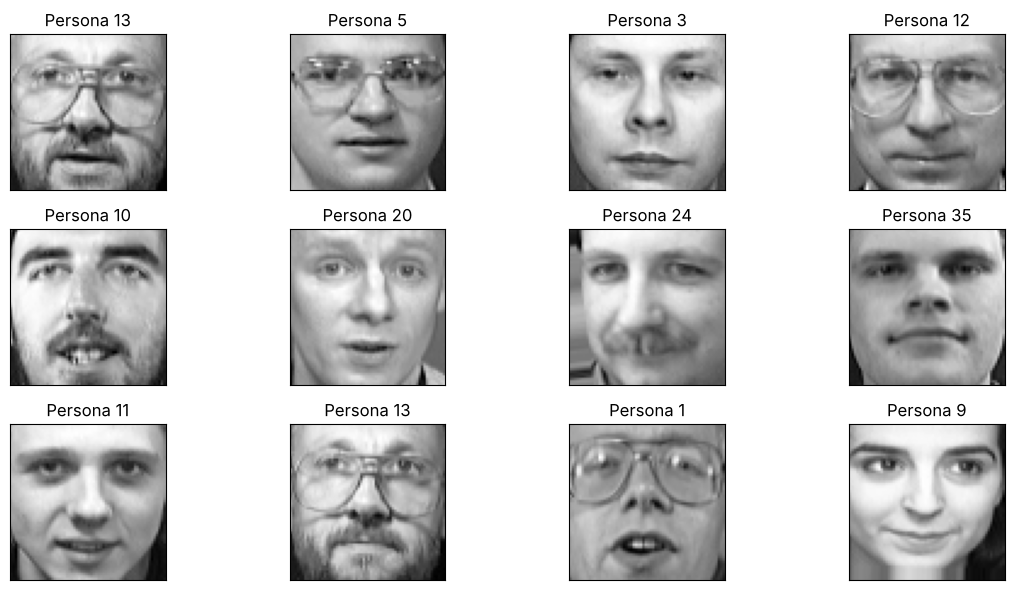

In [4]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Persona {y_train[i]}")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Usaremos una arquitectura fully-connected similar a la vista en clase:

```text
Imagen 64×64
     ↓
Flatten
     ↓
4096 valores
     ↓
Dense(64)
     ↓
ReLU
     ↓
Dense(40)
     ↓
Logits
```

La última capa debe tener una salida por cada clase.

> **Importante:** no añadas `Softmax` al final. Trabajaremos directamente con **logits**.


In [5]:
# TODO 1 — Completar la arquitectura.

model = keras.Sequential([

    keras.Input(shape=(64, 64)),

    layers.Flatten(),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dense(40)
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         2,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,808 (1.01 MB)

 Trainable params: 264,808 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Validación TODO 1

assert isinstance(model, keras.Model)

# Dense(64): 4096*64 + 64
# Dense(40): 64*40 + 40
expected_params = (4096 * 64 + 64) + (64 * 40 + 40)

assert model.count_params() == expected_params, (
    f"Se esperaban {expected_params:,} parámetros, "
    f"pero el modelo tiene {model.count_params():,}."
)

print("✓ Arquitectura correcta.")
print(f"Parámetros entrenables: {model.count_params():,}")


✓ Arquitectura correcta.
Parámetros entrenables: 264,808


### Pregunta 2

¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** Porque `Dense` calcula $W\mathbf{x}+\mathbf{b}$ sobre un **vector** de características, y cada cara llega como una matriz de $64\times64$. `Flatten()` la convierte en un vector de 4 096 valores sin añadir parámetros: solo reordena los píxeles. Así cada una de las 64 neuronas ocultas tiene un peso por píxel ($4096\times64 = 262\,144$ pesos).

### Pregunta 3

¿Por qué la última capa tiene **40 neuronas**?

**Respuesta:** Porque hay **40 personas** (clases 0–39). Cada neurona entrega el logit de una identidad; la persona predicha es la de mayor logit y Softmax convierte los 40 logits en probabilidades.

### Pregunta 4

¿Qué función cumple `ReLU` en la capa oculta?

**Respuesta:** Introduce **no linealidad** ($\max(0,x)$). Sin ella, `Dense(64)` → `Dense(40)` colapsaría en una sola transformación lineal y la red no sería más expresiva que una regresión logística multiclase. Con ReLU, las 64 neuronas aprenden rasgos intermedios que se combinan de forma no lineal. Su punto débil, que aparece en este mismo notebook (sección 5.1), es que una neurona cuya entrada es negativa para todos los ejemplos produce siempre 0, su gradiente es 0 y queda **"muerta"**.


---
# 3. Configurar el entrenamiento

Las etiquetas son números enteros entre:

```text
0 y 39
```

Por eso usaremos:

```python
SparseCategoricalCrossentropy
```

Además:

- el modelo produce **logits**,
- usaremos **Adam**,
- mediremos **accuracy**.

Completa `model.compile()`.


In [7]:
lr_rate = 0.001

# TODO 2 — Configurar loss, optimizer y métrica.

model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=lr_rate
    ),

    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),

    metrics=["accuracy"]
)

print("✓ Modelo configurado.")


✓ Modelo configurado.


### Pregunta 5

¿Por qué usamos:

```python
from_logits=True
```

en la función de pérdida?

**Respuesta:** Porque la última capa `Dense(40)` no tiene activación y produce **logits**, no probabilidades. Con `from_logits=True` la pérdida aplica Softmax y cross-entropy juntas, de forma numéricamente estable (*log-sum-exp*), sin desbordar $e^{z}$ ni calcular $\log 0$. Sin esa opción, Keras trataría los logits como si ya fueran probabilidades y la pérdida y los gradientes serían incorrectos.


---
# 4. Entrenar el modelo

Usaremos:

```python
epochs = 30
batch_size = 32
```

El dataset es pequeño, por lo que el entrenamiento debería ser rápido.

Keras realizará internamente:

```text
Forward pass
      ↓
Calcular loss
      ↓
Backpropagation
      ↓
Actualizar parámetros con Adam
```

Completa la llamada a `fit()`.


In [8]:
epochs = 30
batch_size = 32

# TODO 3 — Entrenar el modelo.

history = model.fit(

    X_train,
    y_train,

    epochs=epochs,
    batch_size=batch_size,

    validation_data=(X_test, y_test),

    shuffle=True,
    verbose=2
)


Epoch 1/30


10/10 - 1s - 76ms/step - accuracy: 0.0156 - loss: 3.9050 - val_accuracy: 0.0250 - val_loss: 3.6889


Epoch 2/30


10/10 - 0s - 11ms/step - accuracy: 0.0250 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889


Epoch 3/30


...

10/10 - 0s - 9ms/step - accuracy: 0.0250 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889


Epoch 29/30


10/10 - 0s - 14ms/step - accuracy: 0.0250 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889


Epoch 30/30


10/10 - 0s - 13ms/step - accuracy: 0.0250 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889


### Pregunta 6

¿Qué representa una **epoch**?

**Respuesta:** Una pasada completa por las **320 imágenes de entrenamiento**. Con `epochs=30` el modelo ve cada cara 30 veces.

### Pregunta 7

¿Qué significa `batch_size=32`?

**Respuesta:** Que Adam actualiza los pesos cada **32 imágenes**: *forward* de 32 ejemplos, pérdida promedio, backpropagation y un paso de actualización. Con 320 imágenes hay $320/32 = 10$ actualizaciones por época (el `10/10` que muestra Keras), es decir, solo 300 actualizaciones en todo el entrenamiento.


---
## 4.1 Visualizar el entrenamiento

Esta parte está resuelta.

El dataset tiene muy pocos ejemplos comparado con el número de parámetros de la red.

Observa cuidadosamente la diferencia entre entrenamiento y validación.


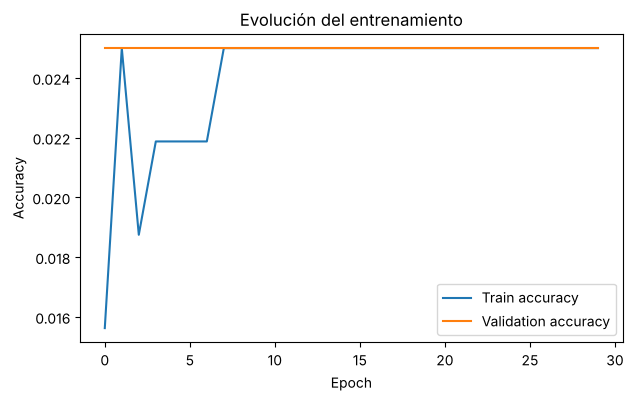

In [9]:
plt.figure(figsize=(7, 4))

plt.plot(
    history.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()

plt.show()


### Pregunta 8

Observando la gráfica:

- ¿El accuracy de entrenamiento sigue aumentando?
- ¿El accuracy de validación se comporta igual?
- ¿Observas evidencia de **overfitting**?

**Respuesta:**

- **No.** Con la configuración pedida la accuracy de entrenamiento **no aumenta**: se queda en ≈ 0.025 (2.5 %, igual que adivinar al azar entre 40 personas) y la loss queda fija en 3.689 ≈ $\ln 40$ desde la segunda época.
- La de validación se comporta igual: una línea plana en 0.025.
- **No hay overfitting, porque no hay aprendizaje.** Las dos curvas son idénticas y planas. Es un caso extremo de *underfitting*: el modelo colapsó y predice la misma distribución uniforme para cualquier cara. La sección 5.1 muestra la causa: **las 64 neuronas ReLU murieron**.

Con la misma red entrenada sobre **entradas centradas** (sección 5.1) sí aparece el comportamiento que la guía esperaba: la accuracy de entrenamiento sube hasta **100 %** en la época 10 y se queda ahí, mientras que la de validación se estanca en **≈ 94–95 %**. La brecha de ≈ 5 puntos y la diferencia de loss (0.01 en train frente a 0.26 en test) sí son evidencia de **overfitting moderado**: la red memoriza perfectamente las 320 imágenes de entrenamiento y generaliza algo peor.


---
# 5. Evaluar el modelo

Ahora evaluaremos el modelo sobre imágenes que no fueron utilizadas para actualizar sus parámetros.

Completa `evaluate()`.


In [10]:
# TODO 4 — Evaluar.

test_loss, test_accuracy = model.evaluate(

    X_test,
    y_test,

    batch_size=batch_size,
    verbose=0
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")

train_loss, train_accuracy = model.evaluate(X_train, y_train, batch_size=batch_size, verbose=0)
print(f"\nTrain accuracy: {train_accuracy:.4f}  (brecha train - test = {train_accuracy - test_accuracy:.4f})")
print(f"Parámetros del modelo: {model.count_params():,} | imágenes de entrenamiento: {len(X_train)}")


Test loss     : 3.6889
Test accuracy : 0.0250
Accuracy (%)  : 2.50%



Train accuracy: 0.0250  (brecha train - test = 0.0000)
Parámetros del modelo: 264,808 | imágenes de entrenamiento: 320


### Pregunta 9

Tenemos **40 clases**, pero solamente **320 imágenes de entrenamiento**.

¿Crees que la cantidad de datos es grande o pequeña para una red con cientos de miles de parámetros?

**Respuesta:** **Muy pequeña.** La red tiene **264 808 parámetros** y solo 320 imágenes de entrenamiento, es decir, **8 por persona** y unos **830 parámetros por cada imagen**. Con tantos grados de libertad la red puede memorizar cada foto de entrenamiento sin aprender rasgos que generalicen. Eso se ve en el modelo corregido: 100 % en train frente a 95 % en test. Además, con tan pocos datos hay muy pocas actualizaciones (10 por época), y el entrenamiento es frágil: una mala dinámica en los primeros pasos, como el colapso de las ReLU de la sección 5.1, no se corrige.

Que aun así se llegue a ≈ 95 % al centrar los datos se debe a que el problema es "fácil" en un sentido: las fotos de cada persona se tomaron en condiciones muy controladas (fondo oscuro, rostro centrado, poca variación), así que basta con comparar patrones de píxeles bastante estables.


---
## 5.1 Diagnóstico: el modelo no aprendió

El resultado anterior es **igual al azar** ($1/40 = 2.5\,\%$) y la loss quedó fija en $\ln 40 \approx 3.689$ desde la segunda época: la red asigna la misma probabilidad a las 40 personas. Antes de responder las preguntas conviene entender por qué. La celda siguiente:

1. cuenta cuántas neuronas de la capa oculta siguen activas (**dying ReLU**);
2. entrena **la misma arquitectura con los mismos hiperparámetros** cambiando una sola cosa: se **centran** los píxeles restando la imagen media del conjunto de entrenamiento.

Probé con varias semillas (0, 1, 2, 3, 7 y 42) y el modelo original colapsa en todas, con 0–2 neuronas vivas de 64. No es mala suerte de la semilla, sino un problema de la configuración.


Neuronas ReLU vivas: 0 de 64
Loss final de entrenamiento: 3.6890  vs  ln(40) = 3.6889


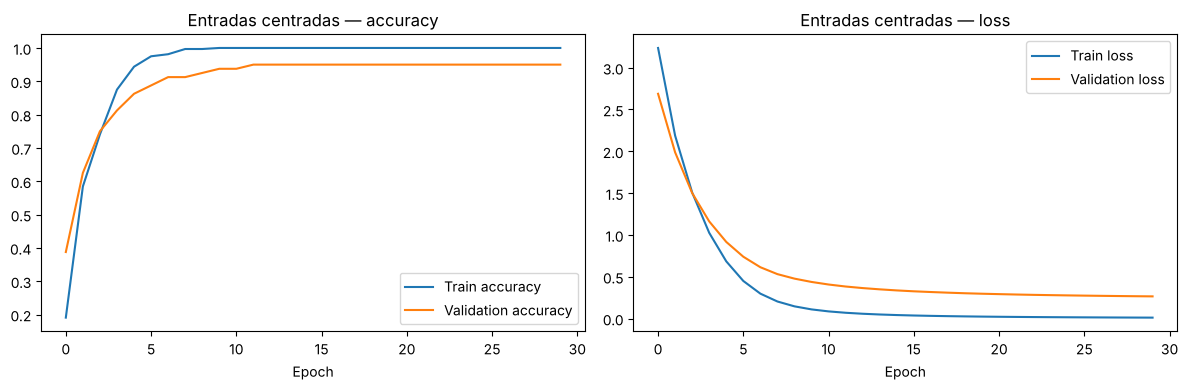

Modelo con entradas centradas -> train acc: 1.0000 | test acc: 0.9500 | train loss: 0.0103 | test loss: 0.2649
  epoch  1: train acc 0.191 | val acc 0.387 | val loss 2.688
  epoch  5: train acc 0.944 | val acc 0.863 | val loss 0.916
  epoch 10: train acc 1.000 | val acc 0.938 | val loss 0.437
  epoch 20: train acc 1.000 | val acc 0.950 | val loss 0.297
  epoch 30: train acc 1.000 | val acc 0.950 | val loss 0.265

Errores en test (índice: real -> predicha): [(10, 25, 2), (14, 9, 7), (48, 31, 14), (75, 0, 23)]


In [11]:
# Diagnóstico 1: ¿cuántas neuronas ReLU de la capa oculta siguen "vivas"?
# Una neurona está muerta si su salida es 0 para TODAS las imágenes de entrenamiento:
# entonces su gradiente también es 0 y ya no puede recuperarse.
hidden = keras.Model(model.inputs[0], model.layers[1].output)
h_out = keras.ops.convert_to_numpy(hidden(X_train, training=False))
vivas = int((h_out.max(axis=0) > 0).sum())
print(f"Neuronas ReLU vivas: {vivas} de {h_out.shape[1]}")
print(f"Loss final de entrenamiento: {history.history['loss'][-1]:.4f}  vs  ln(40) = {np.log(40):.4f}")

# Diagnóstico 2: misma arquitectura, mismo optimizador, mismas épocas y batch;
# único cambio: centrar los píxeles restando la imagen media de ENTRENAMIENTO.
mean_face = X_train.mean(axis=0)
X_train_c = X_train - mean_face
X_test_c = X_test - mean_face          # se usa la media de train: sin fuga de información

keras.utils.set_random_seed(SEED)
model_c = keras.Sequential([
    keras.Input(shape=(64, 64)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(40),
])
model_c.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)
history_c = model_c.fit(
    X_train_c, y_train,
    epochs=epochs, batch_size=batch_size,
    validation_data=(X_test_c, y_test),
    shuffle=True, verbose=0,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_c.history["accuracy"], label="Train accuracy")
axes[0].plot(history_c.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Entradas centradas — accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history_c.history["loss"], label="Train loss")
axes[1].plot(history_c.history["val_loss"], label="Validation loss")
axes[1].set_title("Entradas centradas — loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

tr_loss_c, tr_acc_c = model_c.evaluate(X_train_c, y_train, verbose=0)
te_loss_c, te_acc_c = model_c.evaluate(X_test_c, y_test, verbose=0)
print(f"Modelo con entradas centradas -> train acc: {tr_acc_c:.4f} | test acc: {te_acc_c:.4f} | "
      f"train loss: {tr_loss_c:.4f} | test loss: {te_loss_c:.4f}")
for ep in [0, 4, 9, 19, 29]:
    print(f"  epoch {ep + 1:2d}: train acc {history_c.history['accuracy'][ep]:.3f} | "
          f"val acc {history_c.history['val_accuracy'][ep]:.3f} | val loss {history_c.history['val_loss'][ep]:.3f}")

pred_c = np.argmax(keras.ops.convert_to_numpy(model_c(X_test_c, training=False)), axis=1)
errores = np.flatnonzero(pred_c != y_test)
print("\nErrores en test (índice: real -> predicha):", [(int(i), int(y_test[i]), int(pred_c[i])) for i in errores])


**¿Por qué murieron las ReLU y por qué centrar lo corrige?**

- Los píxeles de Olivetti están en $[0,1]$: **todas las entradas son positivas** y muy correlacionadas (4 096 píxeles de caras parecidas). La pre-activación de cada neurona oculta es $z = \mathbf{w}^\top\mathbf{x} + b$, y como todas las $x_i \ge 0$, el gradiente respecto a todos los pesos de una neurona tiene **el mismo signo** para un ejemplo dado.
- En las primeras actualizaciones, Adam (que normaliza el tamaño del paso) mueve los 4 096 pesos de cada neurona a la vez en la misma dirección. Basta un paso que empuje $\mathbf{w}^\top\mathbf{x}$ hacia valores negativos para **todas** las caras para que la neurona produzca 0 siempre. Su gradiente pasa a ser 0 y ya no se recupera. Así murieron las 64 neuronas: la capa oculta entrega un vector de ceros, los logits quedan constantes y la loss se clava en $\ln 40$.
- Al **restar la cara media** de entrenamiento, cada píxel queda con media cero y valores positivos y negativos. Los gradientes ya no comparten signo, $z$ se reparte alrededor de 0 para distintas caras y las neuronas no se apagan en bloque. Con exactamente la misma red, el mismo optimizador y las mismas épocas, el modelo pasa de **2.5 % a 95 %** en test.
- Es la misma razón por la que en la práctica se **estandarizan** las entradas, como el `StandardScaler` dentro del pipeline de la lectura 6. La media se calcula **solo con entrenamiento** y se aplica igual a test.

Las respuestas a las preguntas 8, 9 y a la reflexión final usan ambos resultados: el del modelo pedido y el del modelo con entradas centradas.


---
# 6. Logits y Softmax

La salida de nuestro modelo tiene forma:

```text
(batch_size, 40)
```

Cada uno de los 40 valores corresponde al **logit** asociado a una persona.

Los logits no son probabilidades.

Para convertirlos en probabilidades usamos:

```python
keras.ops.softmax(...)
```


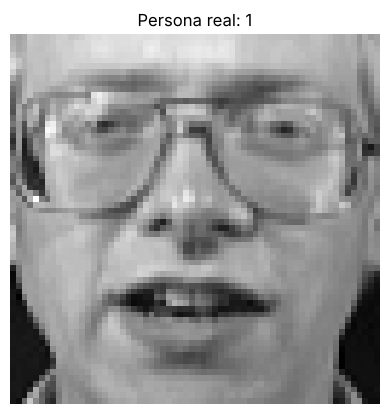

Shape de logits: (1, 40)

Primeros 10 logits:
[ 0.00078378 -0.00700769  0.00334249 -0.00296516 -0.00047903 -0.00141983
 -0.00902546  0.00582534 -0.00014707  0.00095134]


In [12]:
index = 0

image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Persona real: {true_class}")
plt.axis("off")
plt.show()

# Añadimos dimensión de batch:
# (64,64) -> (1,64,64)
image_batch = np.expand_dims(image, axis=0)

# Forward pass.
logits = model(
    image_batch,
    training=False
)

print("Shape de logits:", logits.shape)
print("\nPrimeros 10 logits:")
print(
    keras.ops.convert_to_numpy(logits)[0, :10]
)


In [13]:
# TODO 5 — Convertir logits a probabilidades.

probabilities = keras.ops.softmax(logits)

# TODO 6 — Obtener la clase con mayor probabilidad.

prediction = keras.ops.argmax(
    probabilities,
    axis=1
)

prediction = int(
    keras.ops.convert_to_numpy(prediction)[0]
)

print()
print("Persona real     :", true_class)
print("Persona predicha :", prediction)



Persona real     : 1
Persona predicha : 10


In [14]:
# Revisamos las cinco clases con mayor probabilidad.

probabilities_np = keras.ops.convert_to_numpy(
    probabilities
)[0]

top5 = np.argsort(
    probabilities_np
)[-5:][::-1]

print("Top 5 predicciones:\n")

for class_id in top5:
    print(
        f"Persona {class_id:2d}: "
        f"{probabilities_np[class_id]:.4f}"
    )

print(
    "\nSuma de probabilidades:",
    probabilities_np.sum()
)


Top 5 predicciones:

Persona 10: 0.0252
Persona 17: 0.0252
Persona  7: 0.0251
Persona 26: 0.0251
Persona 19: 0.0251

Suma de probabilidades: 1.0


### Pregunta 10

¿Por qué la suma de las 40 probabilidades obtenidas con `Softmax` debe ser aproximadamente `1`?

**Respuesta:** Porque Softmax divide cada exponencial entre la suma de todas:

$$
p_k = \frac{e^{z_k}}{\sum_{j=1}^{40} e^{z_j}} \;\Rightarrow\; \sum_{k=1}^{40} p_k = 1, \quad p_k > 0.
$$

El resultado es una **distribución de probabilidad** sobre 40 identidades mutuamente excluyentes: cada cara es exactamente de una persona. El "aproximadamente" se debe al redondeo en `float32`.

Aquí se ve un caso ilustrativo: como el modelo colapsó, todos los logits son ≈ 0 y Softmax reparte la probabilidad casi uniformemente (≈ 0.025 = 1/40 para cada persona). Las probabilidades siguen sumando 1, pero ninguna clase destaca. La "predicción" es casi un desempate arbitrario y en este caso es incorrecta.


---
# 7. Visualizar varias predicciones

Esta parte está resuelta.

Observa especialmente los casos en los que el modelo se equivoca.


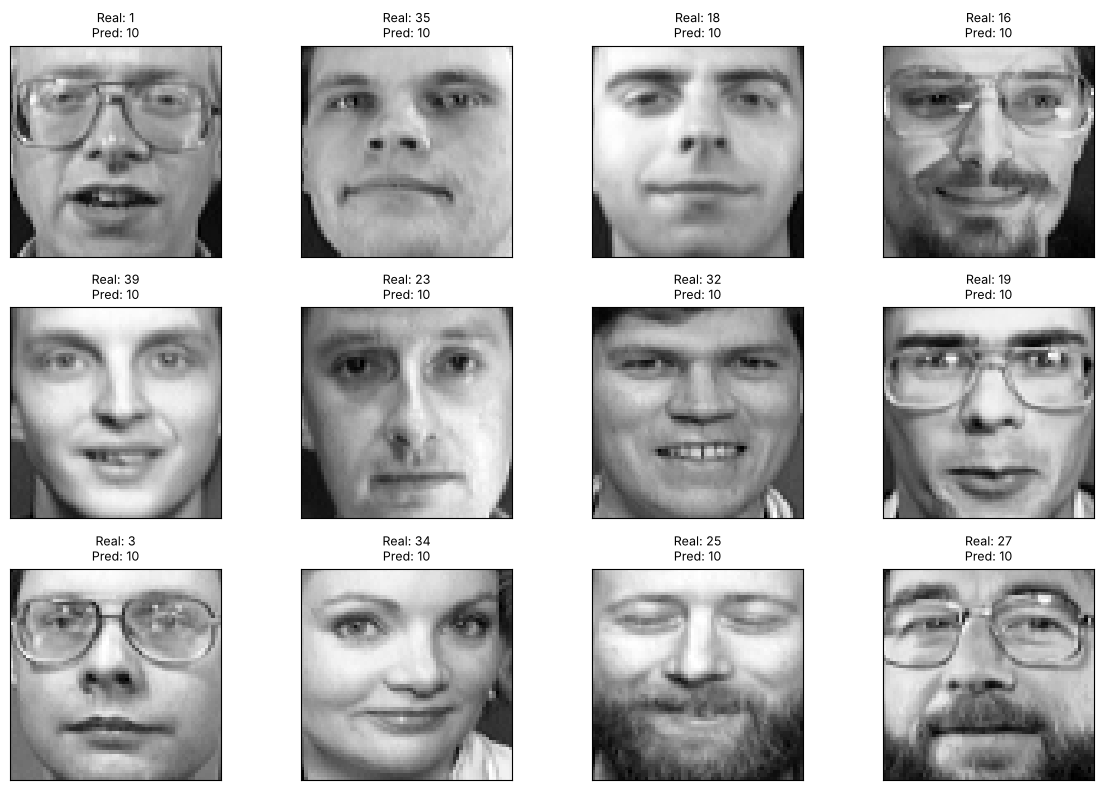

In [15]:
n = 12

logits_batch = model(
    X_test[:n],
    training=False
)

predictions = keras.ops.argmax(
    logits_batch,
    axis=1
)

predictions = keras.ops.convert_to_numpy(
    predictions
)

plt.figure(figsize=(12, 8))

for i in range(n):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        X_test[i],
        cmap="gray"
    )

    real = y_test[i]
    pred = predictions[i]

    plt.title(
        f"Real: {real}\nPred: {pred}",
        fontsize=9
    )

    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 8. Reflexión final

Responde brevemente.

### 1. ¿Cuál fue el accuracy final del modelo?

**Respuesta:** Con la configuración pedida, **2.5 %** en test (y 2.5 % en train): exactamente el nivel del azar para 40 clases, porque la red colapsó. Con la misma arquitectura e hiperparámetros, pero restando a cada imagen la cara media de entrenamiento, el accuracy final es **95 %** en test (76 de 80 caras; 4 errores) y 100 % en entrenamiento.

### 2. ¿Observaste overfitting? ¿Qué evidencia utilizaste?

**Respuesta:** En el modelo original, **no**: train y validación son líneas planas idénticas en 2.5 %, lo que indica falta total de aprendizaje (*underfitting* por neuronas muertas). En el modelo con entradas centradas, **sí, moderado**: la accuracy de entrenamiento llega a 100 % desde la época 10, mientras la de validación se estanca en ≈ 95 %, y la loss de entrenamiento (≈ 0.01) es mucho menor que la de validación (≈ 0.26). La red memorizó el conjunto de entrenamiento y generaliza algo peor.

### 3. ¿Qué ocurre cuando tenemos muchos parámetros pero pocos ejemplos de entrenamiento?

**Respuesta:** La red tiene capacidad de sobra para **memorizar** los ejemplos, incluido su ruido (iluminación o gesto de una foto concreta), en lugar de aprender rasgos generales. La pérdida de entrenamiento llega casi a cero, pero el error en datos nuevos se queda más alto: **overfitting**. Además, las estimaciones son poco confiables (con 80 imágenes de test cada error vale 1.25 puntos) y el entrenamiento es sensible a la inicialización y a la escala de los datos. Para mitigarlo se usan regularización (L2, Dropout), *early stopping*, *data augmentation*, modelos más pequeños o arquitecturas con menos parámetros como las CNN.

### 4. Después de `Flatten()`, una cara de 64×64 se convierte en un vector de 4096 números.

¿Qué información sobre la estructura de la imagen deja de representar explícitamente esta transformación?

**Respuesta:** La **vecindad espacial** entre píxeles. El vector no dice qué píxeles están juntos ni la posición relativa de ojos, nariz y boca. Rasgos locales como bordes, contornos o la forma de las cejas dependen de grupos de píxeles cercanos, y tras aplanar la red debe aprenderlos por separado para cada posición. Tampoco hay invariancia a pequeños desplazamientos: si la cara se mueve unos píxeles, el vector cambia por completo aunque la persona sea la misma.

### 5. ¿Crees que una arquitectura diseñada específicamente para imágenes podría aprovechar mejor la información espacial?

**Respuesta:** **Sí: una red convolucional (CNN).** Sus filtros pequeños recorren la imagen y detectan patrones locales (bordes, texturas, partes del rostro) usando la vecindad de los píxeles. El mismo filtro se reutiliza en todas las posiciones, lo que da invariancia aproximada a traslaciones y **muchos menos parámetros**, algo especialmente valioso aquí, donde hay muy pocos datos. Apiladas con *pooling* construyen una jerarquía de rasgos (bordes → ojos y nariz → rostro) más robusta a cambios de expresión, iluminación u orientación que la comparación píxel a píxel de una red fully-connected.

---

## Para pensar

Nuestra red recibe:

```text
64 × 64
   ↓
Flatten
   ↓
4096 números
   ↓
Dense
```

Pero una imagen tiene una estructura espacial:

- píxeles cercanos están relacionados,
- existen bordes,
- existen formas,
- existen patrones locales.

Una red fully-connected no incorpora explícitamente esa estructura.

Esto motiva una arquitectura diseñada específicamente para imágenes:

> **Convolutional Neural Networks (CNNs)**


---
# Resumen

En este ejercicio aplicaste nuevamente la receta básica de entrenamiento de una red neuronal:

```text
Dataset
   ↓
Train / Test split
   ↓
Sequential
   ↓
Flatten
   ↓
Dense + ReLU
   ↓
Dense(40)
   ↓
Cross-Entropy
   ↓
Adam
   ↓
fit()
   ↓
evaluate()
```

Los componentes de Keras son los mismos que usamos en clase.

Lo que cambió fue:

- el dataset,
- el tamaño de las imágenes,
- el número de clases,
- y la dificultad del problema.
